# Querying the three case-study deposits as one graph

Companion notebook of *How to Publish Five-Star Battery Data*. It loads the JSON-LD metadata of the AURORA, MORROW and Microsoft deposits into one RDF dataset, one named graph per deposit, runs SPARQL queries across them, and in section 10 reads the data files the metadata points to. Sections 1 to 8 run offline on the bundled files, section 9 uses the network, and section 10 needs the data files.

In [1]:
import collections
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path

import pandas as pd
import rdflib
from pyld import jsonld
from rdflib import Dataset, URIRef

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

ROOT = Path.cwd()
META, CTX, RESULTS = ROOT / "metadata", ROOT / "contexts", ROOT / "results"
RESULTS.mkdir(exist_ok=True)

# one named graph per deposit, named after the Zenodo record the metadata came from
DEPOSITS = {
    "AURORA": ("https://zenodo.org/records/15481956", sorted((META / "aurora").glob("*.metadata.json"))),
    "MORROW": ("https://zenodo.org/records/24261116", [META / "morrow" / "battinfo.json"]),
    "Microsoft": ("https://zenodo.org/records/24005755", [META / "microsoft" / "battinfo.json"]),
}
GRAPH_LABEL = {URIRef(g): name for name, (g, _) in DEPOSITS.items()}
RUN_NETWORK = True  # the dereference check in the last section

print("rdflib", rdflib.__version__, "| deposits:", {k: len(v[1]) for k, v in DEPOSITS.items()}, "files")

rdflib 7.6.0 | deposits: {'AURORA': 199, 'MORROW': 1, 'Microsoft': 1} files


## 1. Load the metadata

Each file is expanded against the bundled contexts with PyLD and parsed into its deposit's named graph with rdflib.

In [2]:
CONTEXT_FILES = json.load(open(CTX / "index.json", encoding="utf-8"))


def bundled_loader(url, options=None):
    # answer PyLD's context requests from the bundle, never from the network
    if url in CONTEXT_FILES:
        doc = json.load(open(CTX / CONTEXT_FILES[url], encoding="utf-8"))
        return {"contextUrl": None, "documentUrl": url, "document": doc}
    raise jsonld.JsonLdError(f"context not bundled: {url}", "jsonld.LoadDocumentError")


jsonld.set_document_loader(bundled_loader)

ds = Dataset()
rows = []
for name, (graph_iri, files) in DEPOSITS.items():
    g = ds.graph(URIRef(graph_iri))
    t0 = time.time()
    for f in files:
        expanded = jsonld.expand(json.load(open(f, encoding="utf-8")))
        g.parse(data=json.dumps(expanded), format="json-ld")
    rows.append({"deposit": name, "named graph": graph_iri, "files": len(files), "triples": len(g),
                 "seconds": round(time.time() - t0, 1)})
load = pd.DataFrame(rows)
load.to_csv(RESULTS / "01_load.csv", index=False)
load

,deposit,named graph,files,triples,seconds
0,AURORA,https://zenodo.org/records/15481956,199,113905,9.1
1,MORROW,https://zenodo.org/records/24261116,1,57374,2.6
2,Microsoft,https://zenodo.org/records/24005755,1,138844,6.6


The contexts map labels such as `GraphiteElectrode` to IRIs; the helper below reads them so that queries can use labels. In the AURORA records the `schema` and `rdfs` prefixes end in a letter and are not valid JSON-LD prefixes, so `schema:name` and `rdfs:comment` expand to those literal strings and the queries use them as written.

In [3]:
def context_terms(context):
    # term -> IRI mapping of one context, with prefixes resolved
    terms = {k: (v["@id"] if isinstance(v, dict) and "@id" in v else v) for k, v in context.items()
             if not k.startswith("@") and isinstance(v, (str, dict))}
    terms = {k: v for k, v in terms.items() if isinstance(v, str)}
    out = {}
    for k, v in terms.items():
        if ":" in v and not v.startswith("http") and v.split(":", 1)[0] in terms:
            p, rest = v.split(":", 1)
            out[k] = terms[p] + rest
        else:
            out[k] = v
    return out


TERMS = {}
for url, fname in CONTEXT_FILES.items():
    TERMS.update(context_terms(json.load(open(CTX / fname, encoding="utf-8"))["@context"]))
for f in [META / "morrow" / "battinfo.json", META / "microsoft" / "battinfo.json"]:
    TERMS.update(context_terms(json.load(open(f, encoding="utf-8"))["@context"]))

PREFIXES = {
    "battery": "https://w3id.org/emmo/domain/battery#",
    "echem": "https://w3id.org/emmo/domain/electrochemistry#",
    "substance": "https://w3id.org/emmo/domain/chemical-substance#",
    "chameo": "https://w3id.org/emmo/domain/characterisation-methodology/chameo#",
    "emmo": "https://w3id.org/emmo#",
    "schema": "https://schema.org/",
    "dc": "http://purl.org/dc/elements/1.1/",
    "dcterms": "http://purl.org/dc/terms/",
    "dcat": "http://www.w3.org/ns/dcat#",
    "prov": "http://www.w3.org/ns/prov#",
    "skos": "http://www.w3.org/2004/02/skos/core#",
    "rdfs": "http://www.w3.org/2000/01/rdf-schema#",
    "owl": "http://www.w3.org/2002/07/owl#",
    "spdx": "http://spdx.org/rdf/terms#",
    "csvw": "http://www.w3.org/ns/csvw#",
}
LABEL = {iri: term for term, iri in TERMS.items() if iri.startswith("http")}


def iri(term):
    # the IRI a context assigns to a label, e.g. iri('GraphiteElectrode')
    return TERMS[term]


OPAQUE = ("https://w3id.org/emmo",)  # EMMO IRIs carry no readable local name, so show their context label


def short(value):
    # a readable form of an IRI: the context label, a prefixed name, or the IRI itself
    s = str(value)
    if s.startswith(OPAQUE) and s in LABEL:
        return LABEL[s]
    for p, ns in PREFIXES.items():
        if s.startswith(ns):
            return f"{p}:{s[len(ns):]}"
    return LABEL.get(s, s)


print(len(TERMS), "terms known;", "GraphiteElectrode ->", iri("GraphiteElectrode"))

8133 terms known; GraphiteElectrode -> https://w3id.org/emmo/domain/electrochemistry#electrochemistry_c831d963_629a_41ab_850f_97fb6841b739


In [4]:
import re

PREFIX_BLOCK = "\n".join(f"PREFIX {p}: <{ns}>" for p, ns in PREFIXES.items())


def run(query, label_cols=("g",), shorten=True, on=None):
    # run a SPARQL query over the merged dataset (or over the graph `on`); [[Term]] is replaced by the IRI of that term
    query = re.sub(r"\[\[(\w+)\]\]", lambda m: f"<{iri(m.group(1))}>", query)
    res = (ds if on is None else on).query(PREFIX_BLOCK + "\n" + query)
    cols = [str(v) for v in res.vars]
    rows = []
    for r in res:
        row = {}
        for c in cols:
            v = r[c]
            if c in label_cols and isinstance(v, URIRef) and v in GRAPH_LABEL:
                v = GRAPH_LABEL[v]
            elif isinstance(v, rdflib.Literal):
                v = v.toPython()
            elif shorten and isinstance(v, URIRef):
                v = short(v)
            elif v is not None:
                v = str(v)
            row[c] = v
        rows.append(row)
    return pd.DataFrame(rows, columns=cols)

## 2. What the deposits contain

Records per class and deposit, counted by exact class without reasoning.

In [5]:
CLASSES = ["BatteryCellSpecification", "BatteryCell", "CoinCell", "PouchCell", "PrismaticBattery", "BatteryTest",
           "dcat:Dataset", "dcat:Distribution"]


def class_iris(label):
    if label in TERMS:
        return [iri(label)]
    p, local = label.split(":")
    return [PREFIXES[p] + local, label]  # the IRI and, for the AURORA records, the literal 'schema:X' form


CLASS_OF_IRI = {i: c for c in CLASSES for i in class_iris(c)}
values = " ".join(f"<{i}>" for i in CLASS_OF_IRI)
inventory = run(f'''
SELECT ?g ?type (COUNT(DISTINCT ?s) AS ?n) WHERE {{
  VALUES ?type {{ {values} }}
  GRAPH ?g {{ ?s a ?type }}
}} GROUP BY ?g ?type''', shorten=False)
inventory["class"] = inventory["type"].map(CLASS_OF_IRI)
table = inventory.pivot_table(index="class", columns="g", values="n", aggfunc="sum", fill_value=0)
table = table.reindex([c for c in CLASSES if c in table.index])[list(DEPOSITS)]
table.to_csv(RESULTS / "02_inventory.csv")
table

g,AURORA,MORROW,Microsoft
class,,,
BatteryCellSpecification,0,1,9
BatteryCell,0,111,754
CoinCell,199,0,0
PouchCell,0,0,754
PrismaticBattery,0,111,0
BatteryTest,597,142,772
dcat:Dataset,199,401,773
dcat:Distribution,398,400,772


AURORA types its cells as `CoinCell` only, and each AURORA file holds three tests and two distributions (CSV and Parquet). The MORROW and Microsoft dataset counts include one dataset-series record each. MORROW's 400 distributions share the archive URL as identifier and merge into one node; Microsoft's 772 have their own.

## 3. Licences and identifiers (Stars One and Five)

Every licence statement, and the distinct IRIs of each deposit by namespace.

In [6]:
licences = run('''
SELECT ?g ?property ?licence (COUNT(?s) AS ?statements) WHERE {
  GRAPH ?g { ?s ?property ?licence . FILTER(?property IN (dc:license, dcterms:license, schema:license, <schema:license>)) }
} GROUP BY ?g ?property ?licence ORDER BY ?g''')
licences.to_csv(RESULTS / "03_licences.csv", index=False)
licences

,g,property,licence,statements
0,AURORA,dc:license,https://creativecommons.org/licenses/by/4.0/,199
1,Microsoft,schema:license,https://cdla.dev/permissive-2-0/,774
2,Microsoft,dcterms:license,https://cdla.dev/permissive-2-0/,774
3,MORROW,schema:license,https://spdx.org/licenses/CC-BY-4.0.html,402
4,MORROW,dcterms:license,https://spdx.org/licenses/CC-BY-4.0.html,402


In [7]:
def namespace(u):
    p = urllib.parse.urlparse(u)
    host = p.netloc
    if host == "w3id.org":  # the registry namespace: keep the record type
        parts = [x for x in p.path.split("/") if x]
        return "w3id.org/" + "/".join(parts[:2] if parts[:1] != ["battinfo"] else
                                      (parts[:4] if parts[1:2] == ["id"] else parts[:2]))
    return host or u.split(":")[0] + ":"


counts = collections.defaultdict(lambda: collections.defaultdict(set))
for graph_iri, name in GRAPH_LABEL.items():
    for s, p, o in ds.graph(graph_iri):
        for node in (s, o):
            if isinstance(node, URIRef) and str(node).startswith("http"):
                counts[namespace(str(node))][name].add(str(node))
identifiers = pd.DataFrame({name: {ns: len(d.get(name, ())) for ns, d in counts.items()} for name in DEPOSITS}).fillna(0).astype(int)
identifiers = identifiers[identifiers.sum(axis=1) >= 1].sort_values(list(DEPOSITS), ascending=False)
identifiers.index.name = "distinct IRIs by namespace"
identifiers.to_csv(RESULTS / "03_identifiers.csv")
identifiers

,AURORA,MORROW,Microsoft
distinct IRIs by namespace,,,
doi.org,399,1,1
w3id.org/emmo/domain,44,28,22
w3id.org/emmo,18,22,12
orcid.org,8,6,2
qudt.org,5,0,0
www.w3.org,3,11,8
battery.knowledge-graph.eu,2,0,0
www.wikidata.org,1,0,0
example.org,1,0,0


The `w3id.org/battinfo` namespaces are the deposits' own records; the rest are links out. The AURORA cells and tests are blank nodes.

## 4. Comparable chemistry across deposits (Stars Four and Five)

MORROW and Microsoft type the positive electrode with an ontology class; AURORA gives its active material a formula and a label. The ontology defines `LithiumIronPhosphateElectrode` by its active material and states that material's formula, so the query matches by class where there is one and by formula where there is not. Formulas are compared by composition, so `FeLiO4P` in the ontology and ` LiFePO4` in the records agree and the NMC formulas drop out. The two EMMO modules are bundled in `ontologies/`.

In [8]:
ONTOLOGY_FILES = json.load(open(ROOT / "ontologies" / "index.json", encoding="utf-8"))
ont = rdflib.Graph()
for info in ONTOLOGY_FILES.values():
    ont.parse(ROOT / "ontologies" / info["file"], format="turtle")
print(len(ont), "triples;", ", ".join(info["version"] for info in ONTOLOGY_FILES.values()))


def active_material(electrode_class):
    # the active material the ontology defines the electrode class by, and that material's formula
    return run(f'''
    SELECT ?material ?formula WHERE {{
      [[{electrode_class}]] rdfs:subClassOf ?r .
      ?r owl:onProperty [[hasActiveMaterial]] ; owl:someValuesFrom ?material .
      OPTIONAL {{ ?material [[molecularFormula]] ?formula }}
    }}''', on=ont, shorten=False)


active_material("LithiumIronPhosphateElectrode")

79872 triples; https://w3id.org/emmo/domain/electrochemistry/0.39.0/electrochemistry, https://w3id.org/emmo/domain/chemical-substance/0.15.0/chemical-substance


,material,formula
0,https://w3id.org/emmo/domain/chemical-substance#substance_aa8e9cc4_5f66_4307_b1c8_26fac7653a90,FeLiO4P


In [9]:
def composition(formula):
    # element counts of a formula, so that 'FeLiO4P' (Hill order) and ' LiFePO4' compare equal
    counts = collections.Counter()
    for element, n in re.findall(r"([A-Z][a-z]?)(\d*\.?\d*)", formula.replace(" ", "")):
        counts[element] += float(n) if n else 1.0
    return tuple(sorted(counts.items()))


def chemistry(label, electrode, electrode_class):
    material, formula = active_material(electrode_class).iloc[0]
    q = f'''
    SELECT ?g ?how ?formula (COUNT(DISTINCT ?cell) AS ?cells) (COUNT(DISTINCT ?dataset) AS ?datasets) WHERE {{
      GRAPH ?g {{
        {{
          # registry-style records: the cell conforms to a specification whose described cell has a typed electrode
          ?cell dcterms:conformsTo ?spec .
          ?spec [[isDescriptionFor]] ?described .
          ?described [[{electrode}]] ?el . ?el a [[{electrode_class}]] .
          ?dataset a dcat:Dataset ; schema:about ?cell .
          BIND("electrode typed as {electrode_class}" AS ?how)
        }} UNION {{
          # AURORA records: the electrode is nested in the cell, with its active material
          ?cell [[{electrode}]] / [[hasCoating]] / [[hasActiveMaterial]] ?material .
          ?test [[hasTestObject]] ?cell ; [[hasOutput]] ?dataset .
          {{ ?material a <{material}> . BIND("active material typed as {short(material)}" AS ?how) }}
          UNION
          {{ ?material [[molecularFormula]] / <rdfs:comment> ?formula . BIND("active material by formula" AS ?how) }}
        }}
      }}
    }} GROUP BY ?g ?how ?formula ORDER BY ?g'''
    df = run(q)
    # of the rows matched by formula, keep those whose composition is the one the ontology states
    by_formula = df["how"] == "active material by formula"
    same = df["formula"].map(lambda f: formula is not None and composition(str(f)) == composition(formula))
    df = df[~by_formula | same]
    missing = [d for d in DEPOSITS if d not in set(df["g"])]
    df = pd.concat([df, pd.DataFrame({"g": missing, "how": "no match", "cells": 0, "datasets": 0})], ignore_index=True)
    df.insert(0, "chemistry", label)
    return df


lfp = chemistry("LFP positive electrode", "hasPositiveElectrode", "LithiumIronPhosphateElectrode")
lfp.to_csv(RESULTS / "04_lfp.csv", index=False)
lfp

,chemistry,g,how,formula,cells,datasets
0,LFP positive electrode,AURORA,active material by formula,LiFePO4,32,32
1,LFP positive electrode,MORROW,electrode typed as LithiumIronPhosphateElectrode,NaN,110,400
2,LFP positive electrode,Microsoft,no match,NaN,0,0


The same query for graphite negative electrodes.

In [10]:
graphite = chemistry("graphite negative electrode", "hasNegativeElectrode", "GraphiteElectrode")
graphite.to_csv(RESULTS / "04_graphite.csv", index=False)
graphite

,chemistry,g,how,formula,cells,datasets
0,graphite negative electrode,AURORA,active material typed as Graphite,None,199,199
1,graphite negative electrode,Microsoft,electrode typed as GraphiteElectrode,None,745,772
2,graphite negative electrode,MORROW,electrode typed as GraphiteElectrode,None,110,400


## 5. The provenance chain behind one data file

From the ageing dataset of Microsoft cell A0067 to its test, cell, specification and manufacturer, then the same query on a MORROW file and an AURORA file.

In [11]:
chain_msft = run('''
SELECT ?dataset ?test ?cell ?specification ?manufacturer WHERE {
  GRAPH <https://zenodo.org/records/24005755> {
    ?dataset a dcat:Dataset ; schema:name ?name ; schema:about ?test, ?cell .
    FILTER(CONTAINS(?name, "A0067") && CONTAINS(?name, "1000x1C"))
    ?test a [[BatteryTest]] ; [[hasTestObject]] ?cell .
    ?cell dcterms:conformsTo ?specification .
    ?specification schema:manufacturer / schema:name ?manufacturer .
  }
}''', shorten=False)
chain_msft.T

,0
dataset,https://w3id.org/battinfo/dataset/k27f-z277-b2g4-2btk
test,https://w3id.org/battinfo/test/s4vr-kdbj-ae5s-dmfk
cell,https://w3id.org/battinfo/cell/h0ry-edms-gn2s-fa0v
specification,https://w3id.org/battinfo/spec/m1ad-z9wj-385x-30dh
manufacturer,cm1


In [12]:
chain_morrow = run('''
SELECT ?dataset ?test ?cell ?specification ?manufacturer WHERE {
  GRAPH <https://zenodo.org/records/24261116> {
    ?dataset a dcat:Dataset ; schema:name ?name ; schema:about ?test, ?cell .
    FILTER(CONTAINS(?name, "TRFFC00310") && CONTAINS(?name, "ICycl"))
    ?test a [[BatteryTest]] ; [[hasTestObject]] ?cell .
    ?cell dcterms:conformsTo ?specification .
    ?specification schema:manufacturer / schema:name ?manufacturer .
  }
} LIMIT 1''', shorten=False)
chain_morrow.T

,0
dataset,https://w3id.org/battinfo/id/1001/dataset/a8bh-zf9t-re5p-yjwp
test,https://w3id.org/battinfo/id/1001/test/v2k5-azj2-9edq-cdrv
cell,https://w3id.org/battinfo/cell/0dz2-2awd-ztjn-8v18
specification,https://w3id.org/battinfo/spec/8g1d-skh8-s4nf-67cn
manufacturer,Morrow Batteries


In [13]:
chain_aurora = run('''
SELECT ?dataset ?test ?cell ?manufacturer ?lab WHERE {
  GRAPH <https://zenodo.org/records/15481956> {
    ?test a [[BatteryTest]] ; [[hasTestObject]] ?cell ; [[hasOutput]] ?dataset .
    ?dataset dc:title ?title . FILTER(CONTAINS(?title, "000217"))
    ?cell <schema:manufacturer> ?manufacturer .
    ?dataset dc:publisher ?lab .
  }
} LIMIT 1''', shorten=False)
chain_aurora.T

,0
dataset,N0d68330d0a704a6c81dacb8d83290ac7
test,N15ea6985bac241979e081e3e6b578321
cell,Nbf6aa078c1164605aca0ef676b145fea
manufacturer,https://www.wikidata.org/wiki/Q683116
lab,https://www.wikidata.org/wiki/Q683116


In the MORROW and Microsoft records every link is a `w3id.org` identifier. In the AURORA records the data file is a DOI with a fragment, the manufacturer a Wikidata item, and the test and the cell blank nodes.

## 6. Test conditions across deposits

Tests per ambient temperature. AURORA states it in the characterisation environment of the test procedure, the other two in the measurement parameters of the test; all type it `AmbientCelsiusTemperature`.

In [14]:
temperatures = run('''
SELECT ?g ?T (COUNT(DISTINCT ?test) AS ?tests) WHERE {
  GRAPH ?g {
    ?test a [[BatteryTest]] .
    { ?test chameo:hasMeasurementParameter ?p . ?p a [[AmbientCelsiusTemperature]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?T . }
    UNION
    { ?test chameo:hasMeasurementParameter / chameo:hasCharacterisationEnvironment / [[hasCharacterisationEnvironmentProperty]] ?p .
      ?p a [[AmbientCelsiusTemperature]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?T . }
  }
} GROUP BY ?g ?T ORDER BY ?g ?T''')
temperatures.to_csv(RESULTS / "06_temperatures.csv", index=False)
temperatures.pivot_table(index="T", columns="g", values="tests", aggfunc="sum", fill_value=0)[list(DEPOSITS)]

g,AURORA,MORROW,Microsoft
T,,,
-20,0,9,0
-10,0,3,0
0,0,9,0
10,0,12,0
25,199,54,745
35,0,3,27
40,0,3,0
45,0,32,0
55,0,8,0


## 7. Rated versus measured capacity

Measured beginning-of-life discharge capacity over nominal capacity per cell model, from the cell and specification records.

In [15]:
capacity = run('''
SELECT ?g ?model (COUNT(DISTINCT ?cell) AS ?cells) (MIN(?ratio) AS ?min) (AVG(?ratio) AS ?mean) (MAX(?ratio) AS ?max) ?unit WHERE {
  GRAPH ?g {
    ?cell dcterms:conformsTo ?spec ; [[hasProperty]] ?m .
    ?m a [[DischargingCapacity]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?measured ; [[hasMeasurementUnit]] ?unit .
    ?spec schema:name ?model ; [[isDescriptionFor]] / [[hasProperty]] ?n .
    ?n a [[NominalCapacity]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?nominal .
    BIND(?measured / ?nominal AS ?ratio)
  }
} GROUP BY ?g ?model ?unit ORDER BY ?g ?model''')
for c in ("min", "mean", "max"):
    capacity[c] = capacity[c].astype(float).round(3)
capacity.to_csv(RESULTS / "07_capacity.csv", index=False)
capacity

,g,model,cells,min,mean,max,unit
0,Microsoft,cm1 endt44198,85,1.057,1.069,1.075,Ah
1,Microsoft,cm1 midt44198,87,1.057,1.068,1.072,Ah
2,Microsoft,cm1 mult44198,94,1.048,1.058,1.064,Ah
3,Microsoft,cm2 endt455110,80,1.022,1.032,1.043,Ah
4,Microsoft,cm2 midt455110,80,1.023,1.033,1.038,Ah
5,Microsoft,cm2 mult455110,80,1.025,1.031,1.040,Ah
6,Microsoft,cm3 endt460100,79,1.005,1.014,1.023,Ah
7,Microsoft,cm3 midt460100,80,1.003,1.012,1.020,Ah
8,Microsoft,cm3 mult460100,80,1.010,1.019,1.037,Ah
9,MORROW,Morrow Batteries IFpP45-173-115-B,104,0.963,1.007,1.029,Ah


Nominal energy against capacity times voltage, and specific energy from energy and mass, per specification. MORROW states no nominal energy.

In [16]:
specs = run('''
SELECT ?g ?model ?capacity ?voltage ?energy ?mass ?massUnit WHERE {
  GRAPH ?g {
    ?spec a [[BatteryCellSpecification]] ; schema:name ?model ; [[isDescriptionFor]] ?d .
    ?d [[hasProperty]] ?pc . ?pc a [[NominalCapacity]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?capacity .
    ?d [[hasProperty]] ?pv . ?pv a [[NominalVoltage]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?voltage .
    OPTIONAL { ?d [[hasProperty]] ?pe . ?pe a [[NominalEnergy]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?energy . }
    OPTIONAL { ?d [[hasProperty]] ?pm . ?pm a [[Mass]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?mass ; [[hasMeasurementUnit]] ?massUnit . }
  }
} ORDER BY ?g ?model''')
for c in ("capacity", "voltage", "energy", "mass"):
    specs[c] = pd.to_numeric(specs[c])
specs["capacity x voltage"] = (specs["capacity"] * specs["voltage"]).round(2)
specs["energy / (capacity x voltage)"] = (specs["energy"] / specs["capacity x voltage"]).round(3)
specs["Wh per kg"] = (specs["energy"] / specs["mass"] * 1000).round(0)
specs.to_csv(RESULTS / "07_specifications.csv", index=False)
specs

,g,model,capacity,voltage,energy,mass,massUnit,capacity x voltage,energy / (capacity x voltage),Wh per kg
0,Microsoft,cm1 endt44198,3.000,3.83,11.50,48.0,g,11.49,1.001,240.0
1,Microsoft,cm1 midt44198,2.930,3.83,11.20,48.0,g,11.22,0.998,233.0
2,Microsoft,cm1 mult44198,2.930,3.83,11.20,47.0,g,11.22,0.998,238.0
3,Microsoft,cm2 endt455110,4.400,3.86,17.00,62.0,g,16.98,1.001,274.0
4,Microsoft,cm2 midt455110,4.327,3.86,16.80,62.0,g,16.70,1.006,271.0
5,Microsoft,cm2 mult455110,4.256,3.86,16.50,62.0,g,16.43,1.004,266.0
6,Microsoft,cm3 endt460100,4.320,3.86,16.68,60.0,g,16.68,1.000,278.0
7,Microsoft,cm3 midt460100,4.350,3.87,16.83,60.0,g,16.83,1.000,280.0
8,Microsoft,cm3 mult460100,3.980,3.87,15.40,60.0,g,15.40,1.000,257.0
9,MORROW,Morrow Batteries IFpP45-173-115-B,101.500,3.20,NaN,1999.0,g,324.80,NaN,NaN


## 8. People shared between deposits

Every ORCID iD in the merged graph and the deposits it appears in.

In [17]:
orcids = {name: {u for u in counts.get("orcid.org", {}).get(name, set())} for name in DEPOSITS}
everyone = sorted(set().union(*orcids.values()))
people = pd.DataFrame({name: [u in orcids[name] for u in everyone] for name in DEPOSITS}, index=everyone)
people["deposits"] = people[list(DEPOSITS)].sum(axis=1)
people = people.sort_values("deposits", ascending=False)
people.index.name = "ORCID iD"
people.to_csv(RESULTS / "08_people.csv")
people

,AURORA,MORROW,Microsoft,deposits
ORCID iD,,,,
https://orcid.org/0000-0002-8758-6109,False,True,True,2
https://orcid.org/0000-0001-7229-6101,False,True,False,1
https://orcid.org/0000-0001-5880-5045,False,True,False,1
https://orcid.org/0000-0002-1737-5955,False,True,False,1
https://orcid.org/0000-0002-3297-6054,False,True,False,1
https://orcid.org/0000-0002-4359-5003,True,False,False,1
https://orcid.org/0000-0001-9610-3589,True,False,False,1
https://orcid.org/0000-0002-4426-8717,True,False,False,1
https://orcid.org/0000-0002-5003-1134,True,False,False,1


## 9. Do the identifiers resolve?

One identifier per namespace and deposit, requested over HTTP with `Accept: application/ld+json`. Records not yet registered or published return 404. Set `RUN_NETWORK = False` in the first cell to skip this section.

In [18]:
def dereference(url, timeout=25):
    req = urllib.request.Request(url, headers={"Accept": "application/ld+json, application/json;q=0.9, */*;q=0.1",
                                               "User-Agent": "five-star-queries-notebook"})
    try:
        with urllib.request.urlopen(req, timeout=timeout) as r:
            return r.status, r.headers.get("Content-Type", ""), r.geturl()
    except urllib.error.HTTPError as e:
        return e.code, e.headers.get("Content-Type", ""), e.geturl() if hasattr(e, "geturl") else url
    except Exception as e:  # network errors
        return None, type(e).__name__, url


sample = []
for ns, per_deposit in sorted(counts.items()):
    if ns.startswith(("www.iana.org", "www.w3.org", "w3id.org/emmo", "w3id.org/battery-data-alliance", "spdx.org",
                      "purl.org", "schema.org", "qudt.org", "creativecommons.org", "cdla.dev", "example.org")):
        continue  # vocabularies, media types and licence pages are not records under test
    for name, iris in per_deposit.items():
        sample.append({"deposit": name, "namespace": ns, "identifier": sorted(iris)[0], "n in deposit": len(iris)})
sample = pd.DataFrame(sample).sort_values(["deposit", "namespace"]).reset_index(drop=True)

if RUN_NETWORK:
    out = [dereference(u) for u in sample["identifier"]]
    sample["status"] = [o[0] for o in out]
    sample["content type"] = [o[1].split(";")[0] for o in out]
    sample["resolved to"] = [o[2] for o in out]
    sample.to_csv(RESULTS / "09_dereference.csv", index=False)
else:
    print("network check skipped")
sample

,deposit,namespace,identifier,n in deposit,status,content type,resolved to
0,AURORA,battery.knowledge-graph.eu,https://battery.knowledge-graph.eu/wiki/Item:OSW10266cee36b64c82a8bffcd47ee2d55f,2,200,text/html,https://battery.knowledge-graph.eu/wiki/Item:OSW10266cee36b64c82a8bffcd47ee2d55f
1,AURORA,doi.org,https://doi.org/10.1002/batt.202500155,399,200,application/json,https://api.crossref.org/v1/works/10.1002%2Fbatt.202500155/transform
2,AURORA,orcid.org,https://orcid.org/0000-0001-9610-3589,8,200,application/ld+json,https://pub.orcid.org/v3.0/0000-0001-9610-3589
3,AURORA,www.wikidata.org,https://www.wikidata.org/wiki/Q683116,1,200,text/html,https://www.wikidata.org/wiki/Q683116
4,MORROW,doi.org,https://doi.org/10.5281/zenodo.24261116,1,200,text/html,https://zenodo.org/records/24261116
5,MORROW,orcid.org,https://orcid.org/0000-0001-5880-5045,6,200,application/ld+json,https://pub.orcid.org/v3.0/0000-0001-5880-5045
6,MORROW,w3id.org/battinfo/cell,https://w3id.org/battinfo/cell/0dz2-2awd-ztjn-8v18,110,200,application/ld+json,https://pub-0cc0b5ad760e484a8b2e417f0361c019.r2.dev/cell/0dz2-2awd-ztjn-8v18/resource.jsonld
7,MORROW,w3id.org/battinfo/id/1001/dataset,https://w3id.org/battinfo/id/1001/dataset/06rg-pvz3-53w0-vns6,401,200,application/ld+json,https://pub-0cc0b5ad760e484a8b2e417f0361c019.r2.dev/dataset/06rg-pvz3-53w0-vns6/resource.jsonld
8,MORROW,w3id.org/battinfo/id/1001/spec,https://w3id.org/battinfo/id/1001/spec/271n-0v4b-fbd6-fpmd,14,200,application/ld+json,https://pub-0cc0b5ad760e484a8b2e417f0361c019.r2.dev/test_spec/271n-0v4b-fbd6-fpmd/resource.jsonld
9,MORROW,w3id.org/battinfo/id/1001/test,https://w3id.org/battinfo/id/1001/test/00wv-pk6n-ejwr-hn9h,142,200,application/ld+json,https://pub-0cc0b5ad760e484a8b2e417f0361c019.r2.dev/test/00wv-pk6n-ejwr-hn9h/resource.jsonld


## 10. From the query to the data

One query returns every test that produced a dataset, with the cell, the ambient temperature, the file, its media type, its table schema and its checksum; the MORROW file names come from the schema.org copy of the distribution, since its DCAT distributions merge. The time, current and voltage columns are found through the bundled Battery Data Format table schema by the IRI of their BDF term, with the unit from the schema. Data files are looked up by name under `FIVE_STAR_DATA` (default `data/`), taken out of archives found there, or fetched from the archive the distribution names when `RUN_NETWORK` is on. Without them the section reads its bundled results.

In [19]:
import hashlib
import os
import zipfile

import numpy as np

SCHEMA_FILES = json.load(open(ROOT / "schemas" / "index.json", encoding="utf-8"))
BDF_CONTEXT = context_terms(json.load(open(CTX / CONTEXT_FILES["https://w3id.org/battery-data-alliance/ontology/battery-data-format/context"],
                                          encoding="utf-8"))["@context"])


def expand(compact):
    # a compact IRI of the schema, such as bdf:current_ampere or emmo:Second, in full, through the BDF context
    if ":" in compact and not compact.startswith("http"):
        p, rest = compact.split(":", 1)
        if p in BDF_CONTEXT:
            return BDF_CONTEXT[p] + rest
    return compact


def table_schema(iri):
    return json.load(open(ROOT / "schemas" / SCHEMA_FILES[str(iri)], encoding="utf-8"))


# the quantities the analysis needs, as the BDF terms the schema assigns to columns, in either unit variant
TEST_TIME = {expand("bdf:test_time_second"), expand("bdf:test_time_millisecond")}
CURRENT = {expand("bdf:current_ampere")}
VOLTAGE = {expand("bdf:voltage_volt")}
# the unit IRIs the schema and the records use, as factors to seconds, amperes, volts, ampere hours and centimetres
UNIT = {
    expand("emmo:Second"): 1.0, expand("emmo:MilliSecond"): 1e-3,
    expand("emmo:Ampere"): 1.0, expand("emmo:Volt"): 1.0,
    expand("emmo:AmpereHour"): 1.0, expand("emmo:MilliAmpereHour"): 1e-3,
    expand("emmo:MilliAmpereHourPerSquareCentiMetre"): 1e-3,
    expand("emmo:MilliMetre"): 0.1, expand("unit:MilliM"): 0.1, "https://qudt.org/vocab/unit/MilliM": 0.1,
}


def columns_for(schema, header, terms):
    # the file's column for each wanted term: the schema column that carries the term, matched to the header by its name or a title
    found = {}
    for col in schema["csvw:columns"]:
        term = expand(col["csvw:propertyUrl"])
        if term not in terms:
            continue
        titles = col.get("csvw:titles", [])
        names = [col.get("csvw:name")] + (titles if isinstance(titles, list) else [titles])
        for h in header:
            if h in names:
                found[term] = (h, UNIT[expand(col["hasMeasurementUnit"]["@id"])])
    return found


def read_columns(path, media_type, schema, terms):
    # the wanted columns of a data file, keyed by term and converted to base units, through the schema it conforms to
    if "parquet" in media_type:
        import pyarrow.parquet as pq
        cols = columns_for(schema, pq.ParquetFile(path).schema_arrow.names, terms)
        df = pq.read_table(path, columns=[name for name, _ in cols.values()]).to_pandas()
    else:
        cols = columns_for(schema, list(pd.read_csv(path, nrows=0).columns), terms)
        df = pd.read_csv(path, usecols=[name for name, _ in cols.values()])
    return {term: df[name].to_numpy(dtype=float) * factor for term, (name, factor) in cols.items()}


DATA = Path(os.environ.get("FIVE_STAR_DATA", ROOT / "data"))


def index_files(root):
    idx = {}
    for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
        dirnames[:] = [d for d in dirnames if not d.startswith(".")]
        for f in filenames:
            idx.setdefault(f, Path(dirpath) / f)
    return idx


FILES = index_files(DATA) if DATA.exists() else {}


def fetch_archive(url, endpoint):
    # the archive a distribution names by its download URL, or the archive of the Zenodo record an AURORA dataset points to
    if url is None:
        with urllib.request.urlopen(endpoint, timeout=60) as r:
            url = next(f["links"]["self"] for f in json.load(r)["files"] if f["key"].endswith(".zip"))
    target = DATA / url.split("/files/")[-1].split("/")[0].split("?")[0]
    if not target.exists():
        DATA.mkdir(parents=True, exist_ok=True)
        print("downloading", url)
        with urllib.request.urlopen(url, timeout=120) as r, open(target, "wb") as out:
            while chunk := r.read(1 << 22):
                out.write(chunk)
    return target


def locate(file_name, archive_url=None, endpoint=None):
    # the local path of a data file: in the data folder already, or taken out of the archive it is published in
    if file_name in FILES:
        return FILES[file_name]
    archive = FILES.get(archive_url.rsplit("/", 1)[-1]) if archive_url else None   # the archive itself may be in the data folder
    if archive is None:
        if not RUN_NETWORK:
            return None
        archive = fetch_archive(archive_url, endpoint)
    with zipfile.ZipFile(archive) as z:
        member = next(m for m in z.namelist() if m.endswith(file_name))
        z.extract(member, DATA / "extracted")
    FILES[file_name] = DATA / "extracted" / member
    return FILES[file_name]


def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


print(len(FILES), "data files found")

1828 data files found


In [20]:
tests = run('''
SELECT ?g ?cell ?test ?dataset ?d ?file ?mediaType ?archive ?endpoint ?schema ?sha256 ?T WHERE {
  GRAPH ?g {
    {
      # registry-style records: the file from the schema.org copy of the distribution, the temperature a measurement parameter
      ?test [[hasTestObject]] ?cell ; [[hasOutput]] ?dataset ; chameo:hasMeasurementParameter ?p .
      ?dataset schema:distribution ?d .
      ?d schema:name ?file ; schema:encodingFormat ?mediaType ; schema:contentUrl ?archive ; dcterms:conformsTo ?schema .
      OPTIONAL { ?d schema:sha256 ?sha256 }
    } UNION {
      # AURORA records: the file is the DOI with its path as fragment, the temperature sits in the characterisation environment
      ?test [[hasTestObject]] ?cell ; [[hasOutput]] ?dataset ;
            chameo:hasMeasurementParameter / chameo:hasCharacterisationEnvironment / [[hasCharacterisationEnvironmentProperty]] ?p .
      ?dataset dcat:distribution ?d ; dcat:endpointURL ?endpoint .
      ?d dcat:mediaType ?mediaType ; csvw:tableSchema ?schema .
    }
    ?p a [[AmbientCelsiusTemperature]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?T .
  }
}''', shorten=False)
tests["file"] = tests["file"].fillna(tests["d"].astype(str).str.split("/").str[-1])   # the AURORA path is the DOI fragment
tests["T"] = pd.to_numeric(tests["T"])
tests["parquet"] = tests["mediaType"].astype(str).str.contains("parquet")
tests = (tests.sort_values("parquet", ascending=False).drop_duplicates("dataset")   # Parquet where a deposit offers both
         .sort_values(["g", "file"]).reset_index(drop=True))
pd.DataFrame({"tests": tests.groupby("g")["test"].nunique(), "cells": tests.groupby("g")["cell"].nunique(),
              "files": tests.groupby("g")["file"].count()})

,tests,cells,files
g,,,
AURORA,199,199,199
MORROW,142,110,400
Microsoft,772,745,772


The chemistry of each cell is named by stoichiometry from the formula of its positive active material. The ontology gives the formula for the electrode classes of the MORROW and Microsoft records; the AURORA records state it.

In [21]:
electrodes = run('''
SELECT DISTINCT ?cell ?cls ?formula WHERE {
  GRAPH ?g {
    { ?cell dcterms:conformsTo ?spec . ?spec [[isDescriptionFor]] / [[hasPositiveElectrode]] / a ?cls . }
    UNION
    { ?cell [[hasPositiveElectrode]] / [[hasCoating]] / [[hasActiveMaterial]] / [[molecularFormula]] / <rdfs:comment> ?formula . }
  }
}''', shorten=False)

formula_of_class = {}
for cls in electrodes["cls"].dropna().unique():
    label = short(cls)
    if label in TERMS:
        found = active_material(label)
        if len(found) and found["formula"].iloc[0] is not None:
            formula_of_class[cls] = str(found["formula"].iloc[0])
electrodes["formula"] = electrodes["formula"].fillna(electrodes["cls"].map(formula_of_class))
electrodes = electrodes.dropna(subset=["formula"])


def chemistry_name(formula):
    counts = dict(composition(formula))
    elements = set(counts)
    if {"Fe", "P"} <= elements:
        return "LFP"
    if {"Ni", "Mn", "Co"} <= elements:
        share = np.array([counts["Ni"], counts["Mn"], counts["Co"]])
        return "NMC" + "".join(str(int(round(10 * x))) for x in share / share.sum())
    if "Co" in elements:
        return "LCO"
    return formula.strip()


electrodes["chemistry"] = electrodes["formula"].map(chemistry_name)
chemistry = electrodes.drop_duplicates("cell").set_index("cell")["chemistry"]
tests["chemistry"] = tests["cell"].map(chemistry)
print({cls.split("#")[-1][:40]: f for cls, f in formula_of_class.items()})
tests.groupby(["g", "chemistry"])["cell"].nunique()

{'electrochemistry_1d0f15cb_d6b5_4c27_89ca': 'FeLiO4P', 'electrochemistry_fd7caf39_0a43_4fbf_958e': 'LiCoO2'}


g          chemistry
AURORA     LFP           32
           NMC622       135
           NMC811        32
MORROW     LFP          110
Microsoft  LCO          745
Name: cell, dtype: int64

The reference capacity of a cell is the measured discharge capacity in the MORROW and Microsoft cell records and, for AURORA, the rated areal capacity of the positive electrode times the area from its recorded diameter. Units are read as IRIs.

In [22]:
reference = run('''
SELECT ?g ?cell ?value ?unit ?diameter ?diameterUnit WHERE {
  GRAPH ?g {
    { ?cell [[hasProperty]] ?m . ?m a [[DischargingCapacity]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?value ; [[hasMeasurementUnit]] ?unit . }
    UNION
    { ?cell [[hasPositiveElectrode]] ?pe .
      ?pe [[hasMeasuredProperty]] ?rc . ?rc a [[RatedCapacity]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?value ; [[hasMeasurementUnit]] ?unit .
      ?pe [[hasMeasuredProperty]] ?dm . ?dm a [[Diameter]] ; [[hasNumericalPart]] / [[hasNumberValue]] ?diameter ; [[hasMeasurementUnit]] ?diameterUnit . }
  }
}''', shorten=False)
reference = reference[reference["unit"].astype(str).isin(UNIT)].copy()   # the areal rated capacity, not the gravimetric one


def capacity_ah(r):
    q = float(r["value"]) * UNIT[str(r["unit"])]
    if r["diameter"] is not None and not pd.isna(r["diameter"]):
        q *= np.pi * (float(r["diameter"]) * UNIT[str(r["diameterUnit"])] / 2) ** 2   # areal capacity times the disc area
    return q


reference["capacity_ah"] = reference.apply(capacity_ah, axis=1)
reference = reference.drop_duplicates("cell").set_index("cell")["capacity_ah"]
tests["reference_ah"] = tests["cell"].map(reference)
tests.groupby("g")["reference_ah"].describe()[["count", "min", "max"]]

,count,min,max
g,,,
AURORA,199.0,0.00077,0.002925
MORROW,354.0,97.71000,104.450000
Microsoft,772.0,3.07150,4.588500


Discharge capacity per cycle is the integral of the current over each run of discharge current. Regular cycles are the discharges at the test's own current, within 10 % of its median discharge current, whose capacity lies within 5 % of a centred 25-cycle rolling median. Retention is relative to the median of the first five regular cycles; equivalent full cycles are the cumulative discharge capacity over that reference; the C-rate is the mean discharge current over the reference capacity, assigned to the nearest of 0.2C, 0.3C, 0.5C, 1C, 1.5C and 2C; the upper voltage limit is the highest voltage in the file. A cycling test has at least three regular cycles of at least a fifth of the capacity. Cells whose regular cycles reach less than 85 % of the largest early discharge are on a reduced state-of-charge window. The article's figure takes the cells at 1C over the full window with at least 50 regular cycles, one chemistry per deposit, leaves out cells whose smoothed retention rises by more than 1 % and tests shorter than half the median length of their group, and draws the median of each group over its range up to the end of the shortest remaining test. Files with a checksum in their record are verified before reading.

In [23]:
def discharge_events(t_s, i_a, floor=0.02):
    # contiguous runs of discharge current (negative, by the BDF sign convention): capacity by the trapezoid rule, in Ah
    scale = np.nanpercentile(np.abs(i_a), 99.5) if len(i_a) else 0.0
    on = i_a < -floor * scale if scale > 0 else np.zeros(len(i_a), dtype=bool)
    edges = np.flatnonzero(np.diff(np.concatenate(([0], on.astype(np.int8), [0]))))
    rows = []
    for a, b in edges.reshape(-1, 2):
        if b - a < 2:
            continue
        q = np.trapezoid(-i_a[a:b], t_s[a:b]) / 3600.0
        hours = (t_s[b - 1] - t_s[a]) / 3600.0
        rows.append((a, b, q, q / hours if hours > 0 else np.nan))
    ev = pd.DataFrame(rows, columns=["start", "stop", "q_ah", "i_a"])
    ev["throughput_ah"] = ev["q_ah"].cumsum()
    return ev


def regular_cycles(ev, window=25, tolerance=0.05, current_tolerance=0.10):
    empty = ev.iloc[0:0].assign(cycle=[], retention=[], efc=[])
    big = ev[ev["q_ah"] > 0.2 * ev["q_ah"].quantile(0.95)] if len(ev) else ev   # pulses are not cycles
    if len(big) == 0:
        return empty, np.nan, np.nan
    typical = big["i_a"].median()
    same_rate = big[(big["i_a"] - typical).abs() <= current_tolerance * typical]   # at the test's own current
    median = same_rate["q_ah"].rolling(window, center=True, min_periods=3).median()
    regular = same_rate[(same_rate["q_ah"] > (1 - tolerance) * median) & (same_rate["q_ah"] < (1 + tolerance) * median)].copy()
    if len(regular) == 0:
        return empty, np.nan, np.nan
    q0 = regular["q_ah"].head(5).median()
    regular["cycle"] = np.arange(1, len(regular) + 1)
    regular["retention"] = regular["q_ah"] / q0
    regular["efc"] = regular["throughput_ah"] / q0
    early = big["q_ah"].head(300)
    largest = early[early < 2 * early.median()].max()   # the largest early discharge, a check-up at low rate where there is one
    return regular, q0, q0 / largest


DOD = np.linspace(0, 1, 101)


def discharge_curve(t_s, i_a, v, event):
    # the voltage of one discharge against its depth of discharge, on a common grid
    a, b = int(event["start"]), int(event["stop"])
    q = np.concatenate(([0.0], np.cumsum(-0.5 * (i_a[a + 1:b] + i_a[a:b - 1]) * np.diff(t_s[a:b]))))
    return np.interp(DOD, q / q[-1], v[a:b])


VERIFY_CHECKSUMS = True
summary, curves, shapes, missing = [], {}, {}, []
t0 = time.time()
for r in tests.itertuples():
    aurora = r.g == "AURORA"
    path = locate(r.file, archive_url=None if aurora else str(r.archive), endpoint=str(r.endpoint) if aurora else None)
    if path is None:
        missing.append(r.file)
        continue
    checksum = None
    if VERIFY_CHECKSUMS and isinstance(r.sha256, str):
        checksum = "ok" if sha256_of(path) == r.sha256 else "mismatch"
    arrays = read_columns(path, str(r.mediaType), table_schema(r.schema), TEST_TIME | CURRENT | VOLTAGE)
    t = next(val for k, val in arrays.items() if k in TEST_TIME)
    i = next(val for k, val in arrays.items() if k in CURRENT)
    v = next(val for k, val in arrays.items() if k in VOLTAGE)
    regular, q0, coverage = regular_cycles(discharge_events(t, i))
    n = len(regular)
    v_max = round(float(np.nanpercentile(v, 99.9)) / 0.05) * 0.05 if len(v) else np.nan   # the upper voltage limit, from the data
    summary.append({"deposit": r.g, "cell": r.cell, "test": r.test, "file": r.file, "T": r.T, "chemistry": r.chemistry, "checksum": checksum,
                    "reference_ah": r.reference_ah, "q0_ah": q0, "v_max": v_max, "window_coverage": coverage, "regular_cycles": n,
                    "discharge_c_rate": float(np.median(regular["i_a"].head(50))) / r.reference_ah if n else np.nan,
                    "efc": regular["efc"].iloc[-1] if n else np.nan, "final_retention": regular["retention"].tail(5).median() if n else np.nan})
    if n >= 50:
        curves[r.file] = regular[["cycle", "efc", "retention"]]
        shapes[r.file] = discharge_curve(t, i, v, regular.iloc[0])
if missing:
    print(len(missing), "files not found, e.g.", missing[:3])

# the figure of the article: one chemistry per deposit at 1C, the NMC811 cells of AURORA at the lowest cut-off voltage of their
# batch (4.2 V)
FIGURE = [{"deposit": "AURORA", "chemistry": "NMC811", "v_max": 4.2},
          {"deposit": "MORROW", "chemistry": "LFP", "T": 25}, {"deposit": "Microsoft", "chemistry": "LCO"}]


def in_figure(row):
    return any(all(np.isclose(row[k], v) if isinstance(v, (int, float)) else row[k] == v for k, v in f.items()) for f in FIGURE)


if summary:
    summary = pd.DataFrame(summary)
    summary["cycling"] = (summary["regular_cycles"] >= 3) & (summary["q0_ah"] >= 0.2 * summary["reference_ah"])
    summary["full_window"] = summary["window_coverage"] >= 0.85
    RATES = (0.2, 0.3, 0.5, 1.0, 1.5, 2.0)   # the rates the campaigns used; the measured rate is assigned to the nearest
    summary["rate"] = summary["discharge_c_rate"].map(lambda c: min(RATES, key=lambda k: abs(k - c)) if pd.notna(c) else np.nan)
    summary["group"] = (summary["deposit"] + " " + summary["chemistry"].fillna("unknown") + " to "
                        + summary["v_max"].map(lambda x: f"{x:.2f} V") + " at " + summary["T"].map(lambda T: f"{T:g} °C"))
    summary["one_c"] = summary["cycling"] & summary["full_window"] & (summary["regular_cycles"] >= 50) & (summary["rate"] == 1.0)

    # two more rules for the figure: a rise of more than 1 % in the smoothed retention marks a logging fault, and a test shorter than
    # half the median length of its group stopped early; both are left out, and the band of the figure runs as far as the shortest
    # remaining test
    def max_rise(file):
        if file not in curves:
            return np.nan
        s = curves[file]["retention"].rolling(15, center=True, min_periods=1).median()
        return float((s - s.cummin()).max())

    summary["max_rise"] = summary["file"].map(max_rise)
    candidate = summary["one_c"] & summary.apply(in_figure, axis=1) & (summary["max_rise"] <= 0.01)
    typical = summary[candidate].groupby(["deposit", "chemistry"])["regular_cycles"].transform("median").reindex(summary.index)
    summary["drawn"] = candidate & (summary["regular_cycles"] >= 0.5 * typical)
    drawn_files = set(summary.loc[summary["drawn"], "file"])
    curves = pd.concat([c.assign(file=f) for f, c in curves.items() if f in drawn_files], ignore_index=True)
    shapes = pd.DataFrame([{"file": f, "dod": d, "voltage": vv} for f, arr in shapes.items() if f in drawn_files for d, vv in zip(DOD, arr)])
    summary.round({"reference_ah": 5, "q0_ah": 5, "v_max": 2, "window_coverage": 3, "discharge_c_rate": 3, "efc": 1, "final_retention": 4, "max_rise": 4}).to_csv(RESULTS / "10_tests.csv", index=False)
    curves.round({"efc": 2, "retention": 4}).to_csv(RESULTS / "10_retention.csv", index=False)
    shapes.round({"dod": 2, "voltage": 4}).to_csv(RESULTS / "10_discharge_curves.csv", index=False)
    print(f"{len(summary)} files read in {time.time() - t0:.0f} s; checksums:", summary["checksum"].value_counts(dropna=False).to_dict())
else:
    print("no data files available: using the bundled results")
    summary = pd.read_csv(RESULTS / "10_tests.csv")
    curves = pd.read_csv(RESULTS / "10_retention.csv")
    shapes = pd.read_csv(RESULTS / "10_discharge_curves.csv")
test_map = (summary[summary["cycling"]].groupby(["deposit", "T", "rate"])
            .agg(cells=("cell", "nunique"), tests=("test", "nunique"), cycles=("regular_cycles", "median")).reset_index())
test_map.to_csv(RESULTS / "10_test_map.csv", index=False)
(summary[summary["one_c"]].groupby("group").agg(cells=("cell", "nunique"), cycles=("regular_cycles", "median"), efc=("efc", "max"),
                                                 final_retention=("final_retention", "median"), drawn=("drawn", "all")).round(3))

1371 files read in 133 s; checksums: {'ok': 1172, nan: 199}


,cells,cycles,efc,final_retention,drawn
group,,,,,
AURORA LFP to 3.65 V at 25 °C,32,999.0,819.890,0.464,False
AURORA NMC622 to 10.50 V at 25 °C,2,126.5,124.259,0.502,False
AURORA NMC622 to 4.20 V at 25 °C,68,1000.0,894.843,0.607,False
AURORA NMC622 to 4.40 V at 25 °C,7,966.0,675.292,0.332,False
AURORA NMC622 to 4.60 V at 25 °C,8,675.5,440.748,0.182,False
AURORA NMC622 to 4.80 V at 25 °C,3,192.0,127.140,0.214,False
AURORA NMC622 to 5.70 V at 25 °C,1,192.0,119.228,0.188,False
AURORA NMC622 to 5.80 V at 25 °C,1,211.0,126.877,0.175,False
AURORA NMC622 to 6.50 V at 25 °C,1,204.0,120.574,0.179,False


Groups at 1C over the full window, and the article's selection: NMC811 coin cells of AURORA at the 4.2 V cut-off, MORROW LFP at 25 °C, Microsoft LCO.

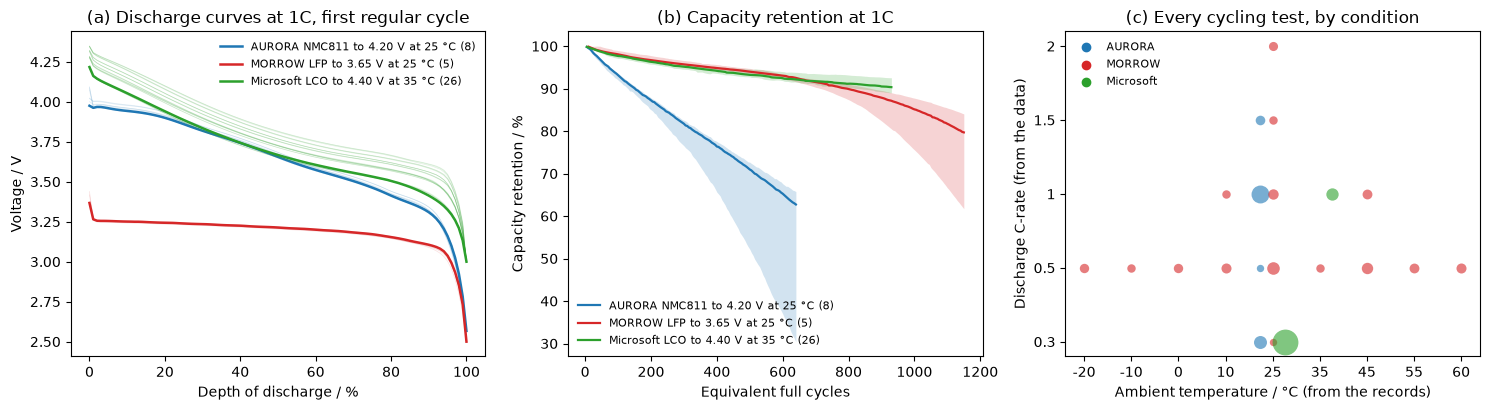

In [24]:
import matplotlib.pyplot as plt

COLOUR = {"AURORA": "#1f77b4", "MORROW": "#d62728", "Microsoft": "#2ca02c"}
drawn = summary[summary["drawn"]]
groups = list(drawn.groupby(["deposit", "chemistry"], sort=False))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# (a) discharge curves at the beginning of the test: the median cell of each group bold, the others faint
for (deposit, chem), g in groups:
    middle = g.iloc[(g["q0_ah"] - g["q0_ah"].median()).abs().argsort().iloc[0]]["file"]
    for file in g["file"]:
        s = shapes[shapes["file"] == file]
        axes[0].plot(100 * s["dod"], s["voltage"], color=COLOUR[deposit], lw=1.8 if file == middle else 0.5,
                     alpha=1.0 if file == middle else 0.15, label=f"{g['group'].iloc[0]} ({len(g)})" if file == middle else None)
axes[0].set_xlabel("Depth of discharge / %")
axes[0].set_ylabel("Voltage / V")
axes[0].set_title("(a) Discharge curves at 1C, first regular cycle")
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
# (b) retention: the median of each group over a band spanning its range, as far as the shortest test of the group ran


def band(group, step=5):
    grid = np.arange(0, group["efc"].max() + step, step)
    rows = [np.interp(grid, g["efc"], g["retention"].rolling(15, center=True, min_periods=1).median(), left=np.nan, right=np.nan)
            for _, g in group.groupby("file")]
    Y = np.vstack(rows)
    ok = ~np.isnan(Y).any(axis=0)
    return grid[ok], np.median(Y[:, ok], axis=0), Y[:, ok].min(axis=0), Y[:, ok].max(axis=0)


for (deposit, chem), g in groups:
    x, med, lo, hi = band(curves[curves["file"].isin(g["file"])])
    axes[1].fill_between(x, 100 * lo, 100 * hi, color=COLOUR[deposit], alpha=0.2, lw=0)
    axes[1].plot(x, 100 * med, color=COLOUR[deposit], lw=1.6, label=f"{g['group'].iloc[0]} ({len(g)})")
axes[1].set_xlabel("Equivalent full cycles")
axes[1].set_ylabel("Capacity retention / %")
axes[1].set_title("(b) Capacity retention at 1C")
axes[1].legend(frameon=False, fontsize=8, loc="lower left")
# (c) every cycling test by the temperature its record states and the rate read from its data
temps = sorted(test_map["T"].unique())
pos = {T: i for i, T in enumerate(temps)}
rates = sorted(test_map["rate"].unique())
row = {r: i for i, r in enumerate(rates)}
offset = {"AURORA": -0.27, "MORROW": 0.0, "Microsoft": 0.27}
for r in test_map.itertuples():
    axes[2].scatter(pos[r.T] + offset[r.deposit], row[r.rate], s=16 + 330 * np.sqrt(r.cells / test_map["cells"].max()), color=COLOUR[r.deposit], alpha=0.6, lw=0)
for deposit in DEPOSITS:
    axes[2].scatter([], [], color=COLOUR[deposit], label=deposit)
axes[2].set_xticks(list(pos.values()))
axes[2].set_xticklabels([f"{T:g}" for T in temps])
axes[2].set_yticks(list(row.values()))
axes[2].set_yticklabels([f"{r:g}" for r in rates])
axes[2].set_xlabel("Ambient temperature / °C (from the records)")
axes[2].set_ylabel("Discharge C-rate (from the data)")
axes[2].set_title("(c) Every cycling test, by condition")
axes[2].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "10_retention.png", dpi=150, bbox_inches="tight")
plt.show()

## Note

An AI agent was used to help generate this notebook.